In [1]:
!pip install diffusers transformers accelerate torch torchvision

In [2]:
import diffusers
import transformers

diffusers.__version__

'0.40.0'

In [3]:
transformers.__version__

'5.18.0'

In [4]:
import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [5]:
from diffusers import StableDiffusionPipeline, StableDiffusionInpaintPipeline
from PIL import Image
import matplotlib.pyplot as plt

def display_image(image):
    plt.imshow(image)
    plt.axis('off')
    plt.show()

## 문장형 vs 키워드형 프롬프트 비교

각 프롬프트마다 같은 seed 5개를 사용해 총 10장을 생성한다. 기존 모델·negative prompt·30 step·guidance 8.5를 유지한다. 비교 이미지의 같은 열은 같은 seed이다.

원문 in the moon은 두 조건에 공통으로 유지한다. 키워드형은 일부 기능어도 생략하므로, 결과는 쉼표 하나의 효과가 아닌 표현 방식 전체의 차이로 해석한다.


/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

...

sentence 4/5 | seed=7 | 1.52s


  0%|          | 0/30 [00:00<?, ?it/s]

sentence 5/5 | seed=99 | 1.52s


  0%|          | 0/30 [00:00<?, ?it/s]

keywords 5/5 | seed=99 | 1.53s


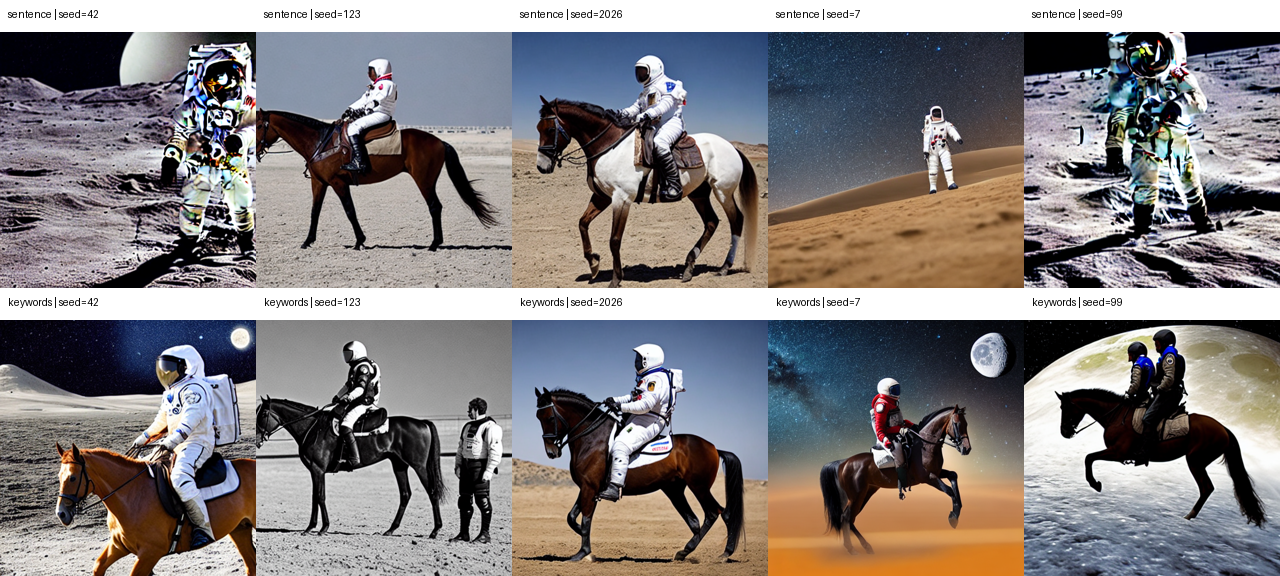

Results: /content/prompt_comparison_results/run_fc52ea8e
총 생성 이미지: 문장형 5장 + 키워드형 5장 = 10장
생성 시간은 모델 로딩·파일 저장을 제외하며 첫 생성의 초기화 비용이 포함될 수 있습니다.
sentence: median 1.52s/image
keywords: median 1.52s/image


In [6]:
# --- 1.1 파이프라인 로드 ---
import csv
import json
import platform
import statistics
import time
import uuid
from pathlib import Path
from IPython.display import display
from PIL import ImageDraw

model_id_text2img = "runwayml/stable-diffusion-v1-5"
dtype = torch.float16 if device == "cuda" else torch.float32
pipe_text2img = StableDiffusionPipeline.from_pretrained(
    model_id_text2img, torch_dtype=dtype
).to(device)
print("Text-to-Image pipeline loaded.")

# --- 1.2 비교 프롬프트 및 공통 설정 ---
PROMPTS = {
    "sentence": "A photo of man riding a horse in the moon wearing astronaut outfits",
    "keywords": "man, riding, horse, moon, space suit",
}
SEEDS = [42, 123, 2026, 7, 99]
images_per_prompt = 5
assert len(SEEDS) == images_per_prompt
negative_prompt = "blurry, deformed, cartoon, painting, illustration, normal, no defect"
num_steps = 30
guidance_scale_val = 8.5
width = height = 512

run_dir = Path("prompt_comparison_results") / f"run_{uuid.uuid4().hex[:8]}"
(run_dir / "images").mkdir(parents=True)
settings = {
    "model_id": model_id_text2img,
    "model_config": dict(pipe_text2img.config),
    "scheduler": type(pipe_text2img.scheduler).__name__,
    "scheduler_config": dict(pipe_text2img.scheduler.config),
    "prompts": PROMPTS,
    "seeds": SEEDS,
    "images_per_prompt": images_per_prompt,
    "negative_prompt": negative_prompt,
    "num_steps": num_steps,
    "guidance_scale": guidance_scale_val,
    "width": width,
    "height": height,
    "generator_device": "cpu",
    "torch_version": torch.__version__,
    "diffusers_version": diffusers.__version__,
    "platform": platform.platform(),
}
(run_dir / "settings.json").write_text(
    json.dumps(settings, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
)

def synchronize_generation():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

# --- 1.3 각 프롬프트당 5장 생성: 총 10회, 추가 워밍업 생성 없음 ---
conditions = list(PROMPTS)
generated_images = {name: [] for name in conditions}
timings = []
timing_fields = ["seed", "condition", "image_file", "generation_seconds", "nsfw_flag"]

with (run_dir / "timings.csv").open("w", encoding="utf-8-sig", newline="") as tf:
    time_writer = csv.DictWriter(tf, fieldnames=timing_fields)
    time_writer.writeheader()

    for index, seed in enumerate(SEEDS):
        # 첫 실행 비용이 한 조건에만 몰리지 않도록 실행 순서를 번갈아 적용한다.
        order = conditions if index % 2 == 0 else conditions[::-1]
        for name in order:
            # 같은 seed를 각 조건에서 새로 적용해 초기 난수 상태를 맞춘다.
            generator = torch.Generator(device="cpu").manual_seed(seed)
            synchronize_generation()
            start = time.perf_counter()
            result = pipe_text2img(
                prompt=PROMPTS[name],
                negative_prompt=negative_prompt,
                num_inference_steps=num_steps,
                guidance_scale=guidance_scale_val,
                num_images_per_prompt=1,
                height=height,
                width=width,
                generator=generator,
            )
            synchronize_generation()
            elapsed = time.perf_counter() - start

            image = result.images[0].convert("RGB")
            relative_file = f"images/{name}_{index + 1}_seed_{seed}.png"
            image.save(run_dir / relative_file)
            generated_images[name].append(image)
            flags = getattr(result, "nsfw_content_detected", None)
            timing = {
                "seed": seed,
                "condition": name,
                "image_file": relative_file,
                "generation_seconds": elapsed,
                "nsfw_flag": flags[0] if flags is not None else "",
            }
            timings.append(timing)
            time_writer.writerow(timing)
            tf.flush()
            print(f"{name} {index + 1}/{images_per_prompt} | seed={seed} | {elapsed:.2f}s")
            del result

assert all(len(images) == images_per_prompt for images in generated_images.values())

# --- 1.4 결과 확인: 위쪽 문장형 5장, 아래쪽 키워드형 5장 ---
tile_size = 256
label_height = 32
comparison_grid = Image.new(
    "RGB", (tile_size * images_per_prompt, (tile_size + label_height) * len(conditions)), "white"
)
draw = ImageDraw.Draw(comparison_grid)
for row, name in enumerate(conditions):
    for column, (seed, image) in enumerate(zip(SEEDS, generated_images[name])):
        x = column * tile_size
        y = row * (tile_size + label_height)
        draw.text((x + 8, y + 8), f"{name} | seed={seed}", fill="black")
        comparison_grid.paste(image.resize((tile_size, tile_size)), (x, y + label_height))
comparison_grid.save(run_dir / "prompt_comparison.png")
display(comparison_grid)
print("Results:", run_dir.resolve())
print("총 생성 이미지: 문장형 5장 + 키워드형 5장 = 10장")
print("생성 시간은 모델 로딩·파일 저장을 제외하며 첫 생성의 초기화 비용이 포함될 수 있습니다.")
for name in conditions:
    seconds = [row["generation_seconds"] for row in timings if row["condition"] == name]
    print(f"{name}: median {statistics.median(seconds):.2f}s/image")


## 모래 보물상자 인페인팅 비교

같은 원본 이미지·마스크·seed 5개로 문장형과 키워드형을 각각 5장 생성한다. 50 step, guidance 8.5를 사용하며 결과는 2행×5열로 표시한다.


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Inpainting pipeline loaded: sd-legacy/stable-diffusion-inpainting (cuda)


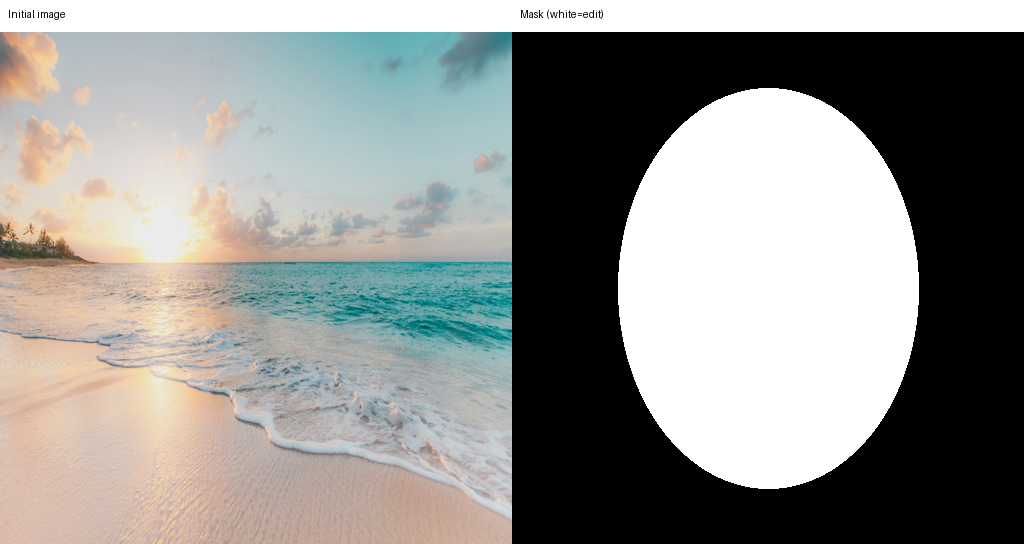

  0%|          | 0/50 [00:00<?, ?it/s]

sentence 1/5 | seed=42 | 2.45s


  0%|          | 0/50 [00:00<?, ?it/s]

keywords 1/5 | seed=42 | 2.45s


  0%|          | 0/50 [00:00<?, ?it/s]

...

sentence 4/5 | seed=7 | 2.42s


  0%|          | 0/50 [00:00<?, ?it/s]

sentence 5/5 | seed=99 | 2.43s


  0%|          | 0/50 [00:00<?, ?it/s]

keywords 5/5 | seed=99 | 2.46s


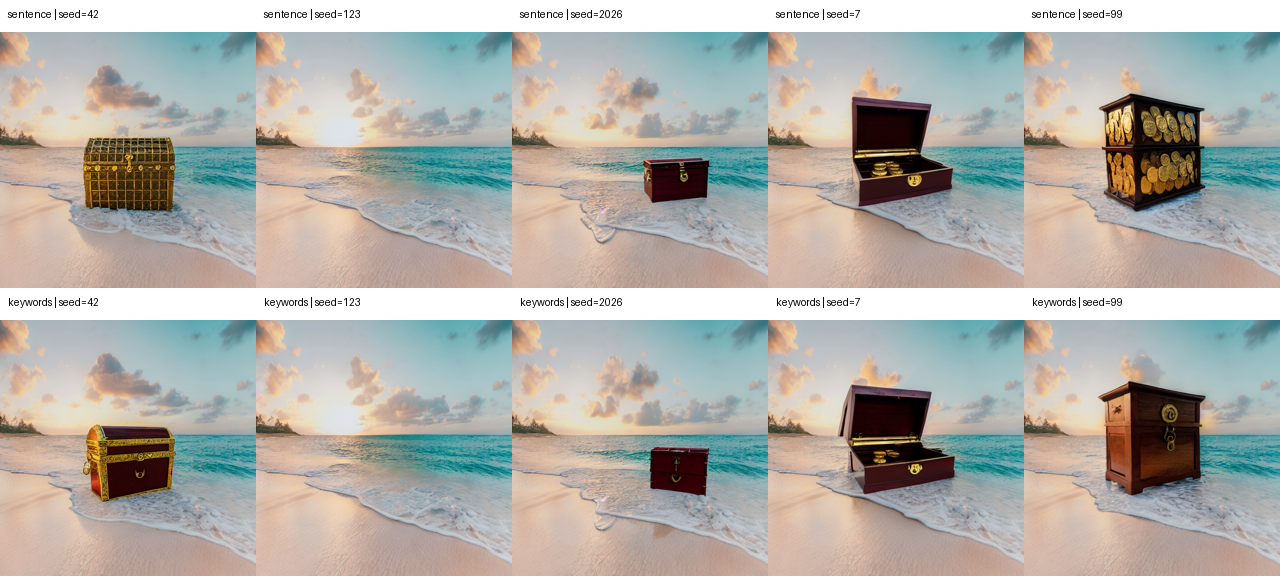

Results: /content/inpaint_comparison_results/run_31ecbc27
보물상자 인페인팅: 문장형 5장 + 키워드형 5장 = 총 10장
sentence: median 2.43s/image
keywords: median 2.45s/image
생성 시간은 파일 저장·표시를 제외하며 첫 생성의 초기화 비용이 포함될 수 있습니다.


In [12]:
import csv
import json
import statistics
import time
import uuid
from io import BytesIO
from pathlib import Path

import requests
import torch
from diffusers import StableDiffusionInpaintPipeline
from IPython.display import display
from PIL import Image, ImageDraw

# --- 인페인팅 모델 로드 ---
inpaint_device = "cuda" if torch.cuda.is_available() else "cpu"
inpaint_dtype = torch.float16 if inpaint_device == "cuda" else torch.float32
model_id_inpaint = "sd-legacy/stable-diffusion-inpainting"
try:
    pipe_inpaint = StableDiffusionInpaintPipeline.from_pretrained(
        model_id_inpaint,
        variant="fp16",
        torch_dtype=inpaint_dtype,
    ).to(inpaint_device)
    print(f"Inpainting pipeline loaded: {model_id_inpaint} ({inpaint_device})")
except Exception as error:
    print(f"Could not load inpainting pipeline: {error}")
    pipe_inpaint = None

if pipe_inpaint is not None:
    # --- 공통 원본 이미지와 마스크 ---
    inpaint_width = inpaint_height = 512
    image_url = (
        "https://images.unsplash.com/photo-1507525428034-b723cf961d3e"
        "?q=80&w=2070&auto=format&fit=crop"
    )
    using_placeholder = False
    try:
        response = requests.get(image_url, timeout=30)
        response.raise_for_status()
        init_image = Image.open(BytesIO(response.content)).convert("RGB").resize(
            (inpaint_width, inpaint_height)
        )
    except Exception as error:
        using_placeholder = True
        print(f"Image load failed: {error}. Using placeholder image.")
        init_image = Image.new("RGB", (inpaint_width, inpaint_height))
        placeholder_draw = ImageDraw.Draw(init_image)
        placeholder_draw.rectangle([0, 0, 512, 280], fill="skyblue")
        placeholder_draw.rectangle([0, 280, 512, 512], fill="goldenrod")
        placeholder_draw.ellipse([400, 60, 440, 100], fill="gold")

    mask_image = Image.new("L", (inpaint_width, inpaint_height), 0)
    ImageDraw.Draw(mask_image).ellipse([106, 56, 406, 456], fill=255)

    # --- 문장형·키워드형 각각 5장 ---
    INPAINT_PROMPTS = {
        "sentence": "A photo of an open treasure chest filled with gold coins.",
        "keywords": "opened, treasure chest, filled, gold coins",
    }
    INPAINT_SEEDS = [42, 123, 2026, 7, 99]
    inpaint_images_per_prompt = 5
    assert len(INPAINT_SEEDS) == inpaint_images_per_prompt
    inpaint_negative_prompt = (
        "blurry, deformed, cartoon, illustration, watermark, text, signature, extra limbs"
    )
    inpaint_num_steps = 50
    inpaint_guidance_scale = 8.5
    inpaint_strength = 1.0
    inpaint_conditions = list(INPAINT_PROMPTS)

    inpaint_run_dir = Path("inpaint_comparison_results") / f"run_{uuid.uuid4().hex[:8]}"
    (inpaint_run_dir / "images").mkdir(parents=True)
    init_image.save(inpaint_run_dir / "init_image.png")
    mask_image.save(inpaint_run_dir / "mask_image.png")
    inpaint_settings = {
        "model_id": model_id_inpaint,
        "model_config": dict(pipe_inpaint.config),
        "scheduler": type(pipe_inpaint.scheduler).__name__,
        "scheduler_config": dict(pipe_inpaint.scheduler.config),
        "prompts": INPAINT_PROMPTS,
        "seeds": INPAINT_SEEDS,
        "images_per_prompt": inpaint_images_per_prompt,
        "image_url": image_url,
        "using_placeholder": using_placeholder,
        "mask_ellipse_box": [106, 56, 406, 456],
        "num_inference_steps": inpaint_num_steps,
        "guidance_scale": inpaint_guidance_scale,
        "strength": inpaint_strength,
        "negative_prompt": inpaint_negative_prompt,
        "width": inpaint_width,
        "height": inpaint_height,
        "dtype": str(inpaint_dtype),
        "torch_version": torch.__version__,
        "generator_device": "cpu",
    }
    (inpaint_run_dir / "settings.json").write_text(
        json.dumps(inpaint_settings, ensure_ascii=False, indent=2, default=str),
        encoding="utf-8",
    )

    input_grid = Image.new("RGB", (inpaint_width * 2, inpaint_height + 32), "white")
    input_draw = ImageDraw.Draw(input_grid)
    input_draw.text((8, 8), "Initial image", fill="black")
    input_draw.text((inpaint_width + 8, 8), "Mask (white=edit)", fill="black")
    input_grid.paste(init_image, (0, 32))
    input_grid.paste(mask_image.convert("RGB"), (inpaint_width, 32))
    input_grid.save(inpaint_run_dir / "input_and_mask.png")
    display(input_grid)

    def synchronize_inpainting():
        if inpaint_device == "cuda":
            torch.cuda.synchronize()

    inpaint_images = {name: [] for name in inpaint_conditions}
    inpaint_timings = []
    inpaint_timing_fields = [
        "seed", "condition", "image_file", "generation_seconds", "nsfw_flag"
    ]
    with (inpaint_run_dir / "timings.csv").open(
        "w", encoding="utf-8-sig", newline=""
    ) as inpaint_timing_file:
        inpaint_time_writer = csv.DictWriter(
            inpaint_timing_file, fieldnames=inpaint_timing_fields
        )
        inpaint_time_writer.writeheader()
        for index, seed in enumerate(INPAINT_SEEDS):
            order = inpaint_conditions if index % 2 == 0 else inpaint_conditions[::-1]
            for name in order:
                generator = torch.Generator(device="cpu").manual_seed(seed)
                synchronize_inpainting()
                start = time.perf_counter()
                result = pipe_inpaint(
                    prompt=INPAINT_PROMPTS[name],
                    image=init_image,
                    mask_image=mask_image,
                    negative_prompt=inpaint_negative_prompt,
                    num_inference_steps=inpaint_num_steps,
                    guidance_scale=inpaint_guidance_scale,
                    strength=inpaint_strength,
                    width=inpaint_width,
                    height=inpaint_height,
                    num_images_per_prompt=1,
                    generator=generator,
                )
                synchronize_inpainting()
                elapsed = time.perf_counter() - start
                output_image = result.images[0].convert("RGB")
                image_file = f"images/{name}_{index + 1}_seed_{seed}.png"
                output_image.save(inpaint_run_dir / image_file)
                inpaint_images[name].append(output_image)
                flags = getattr(result, "nsfw_content_detected", None)
                timing = {
                    "seed": seed,
                    "condition": name,
                    "image_file": image_file,
                    "generation_seconds": elapsed,
                    "nsfw_flag": flags[0] if flags is not None else "",
                }
                inpaint_timings.append(timing)
                inpaint_time_writer.writerow(timing)
                inpaint_timing_file.flush()
                print(f"{name} {index + 1}/5 | seed={seed} | {elapsed:.2f}s")
                del result

    assert all(
        len(images) == inpaint_images_per_prompt for images in inpaint_images.values()
    )

    # --- 결과 표시: 위쪽 문장형 5장, 아래쪽 키워드형 5장 ---
    inpaint_tile_size = 256
    inpaint_label_height = 32
    inpaint_comparison_grid = Image.new(
        "RGB",
        (inpaint_tile_size * inpaint_images_per_prompt,
         (inpaint_tile_size + inpaint_label_height) * len(inpaint_conditions)),
        "white",
    )
    comparison_draw = ImageDraw.Draw(inpaint_comparison_grid)
    for row, name in enumerate(inpaint_conditions):
        for column, (seed, image) in enumerate(zip(INPAINT_SEEDS, inpaint_images[name])):
            x = column * inpaint_tile_size
            y = row * (inpaint_tile_size + inpaint_label_height)
            comparison_draw.text((x + 8, y + 8), f"{name} | seed={seed}", fill="black")
            inpaint_comparison_grid.paste(
                image.resize((inpaint_tile_size, inpaint_tile_size)),
                (x, y + inpaint_label_height),
            )
    inpaint_comparison_grid.save(inpaint_run_dir / "inpaint_comparison.png")
    display(inpaint_comparison_grid)
    print("Results:", inpaint_run_dir.resolve())
    print("보물상자 인페인팅: 문장형 5장 + 키워드형 5장 = 총 10장")
    for name in inpaint_conditions:
        seconds = [
            row["generation_seconds"] for row in inpaint_timings
            if row["condition"] == name
        ]
        print(f"{name}: median {statistics.median(seconds):.2f}s/image")
    print("생성 시간은 파일 저장·표시를 제외하며 첫 생성의 초기화 비용이 포함될 수 있습니다.")
else:
    print("Pipeline not loaded. Cannot run inpainting.")
